# Código

Este arquivo contém todos os códigos utilizados nas análises. Os códigos foram separados em duas partes: a primeira, correspondente à _análise exploratória de dados_, e a segunda, referente ao nosso processo de _modelagem_.



# Análise Exploratória de Dados

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import binned_statistic_2d, gaussian_kde
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid")

dados = pd.read_csv("train.csv").drop(columns="pair_id")
dados.info()
print(dados.head())
print(dados.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   user_avg_stars   4000 non-null   float64
 1   user_n_ratings   4000 non-null   int64  
 2   age              4000 non-null   int64  
 3   share_action     4000 non-null   float64
 4   share_comedy     4000 non-null   float64
 5   share_drama      4000 non-null   float64
 6   movie_avg_stars  4000 non-null   float64
 7   movie_n_ratings  4000 non-null   int64  
 8   genre            4000 non-null   object 
 9   release_year     4000 non-null   int64  
 10  stars            4000 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 343.9+ KB
   user_avg_stars  user_n_ratings  age  share_action  share_comedy  \
0            2.99              15   48         0.315         0.501   
1            3.44              35   57         0.180         0.151   
2            3.91    

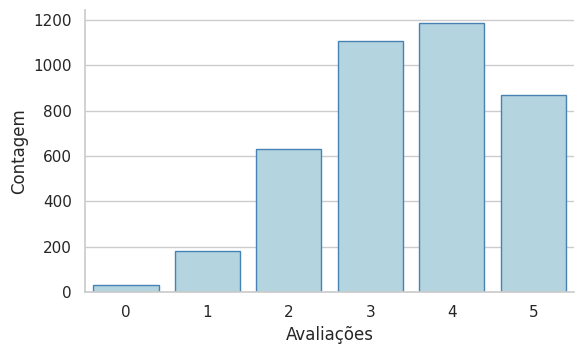

In [2]:
fig, ax = plt.subplots(figsize=(6, 3.7))
sns.countplot(data=dados, x="stars", color="lightblue", edgecolor="steelblue", ax=ax)
ax.set_xlabel("Avaliações")
ax.set_ylabel("Contagem")
sns.despine()
plt.tight_layout()
plt.show()

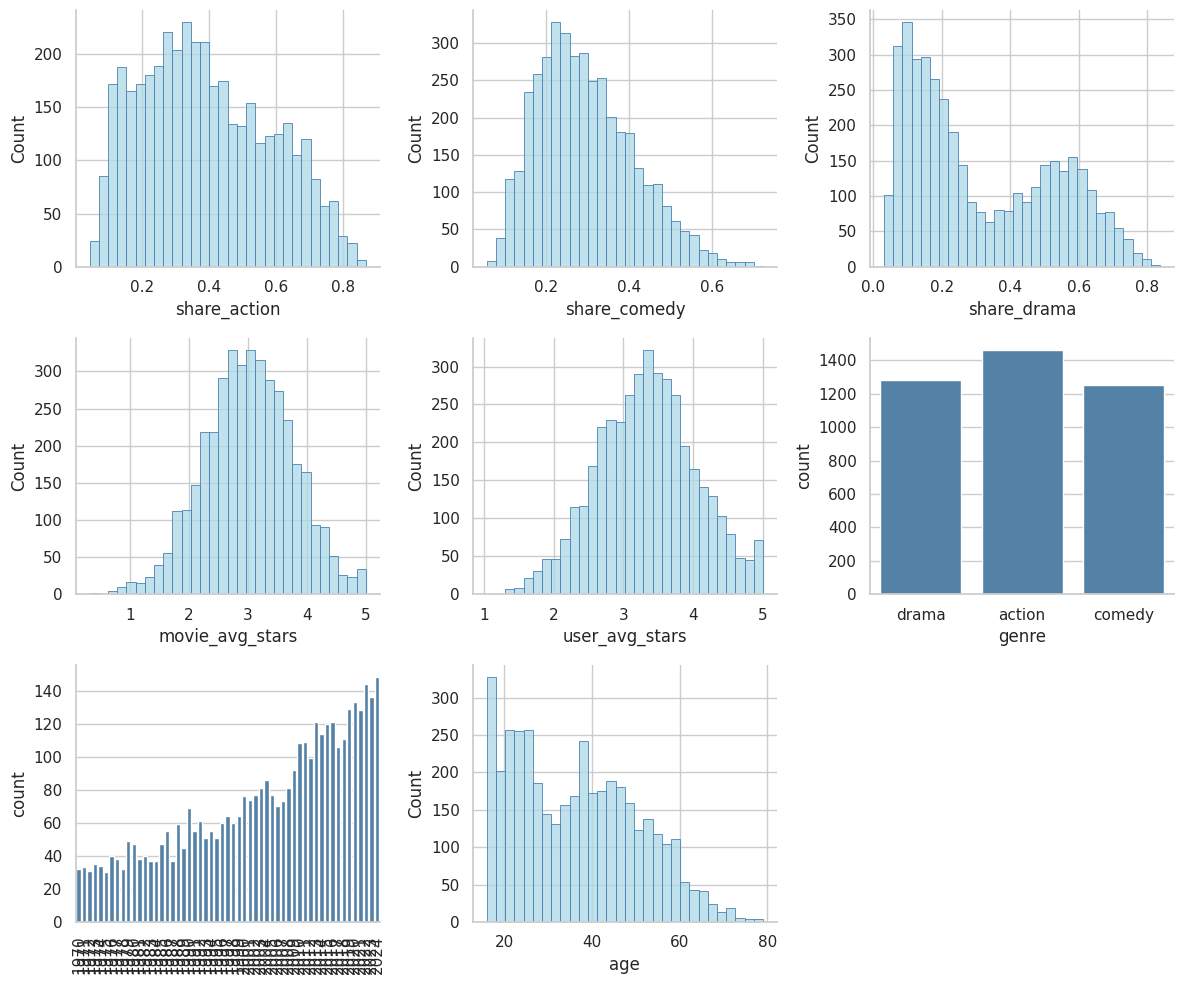

In [3]:
fig, eixos = plt.subplots(3, 3, figsize=(12, 10))
eixos = eixos.ravel()
colunas_hist = ["share_action", "share_comedy", "share_drama", "movie_avg_stars", "user_avg_stars"]
for ax, coluna in zip(eixos[:5], colunas_hist):
    sns.histplot(data=dados, x=coluna, bins=30, color="lightblue", edgecolor="steelblue", ax=ax)
sns.countplot(data=dados, x="genre", color="steelblue", ax=eixos[5])
sns.countplot(data=dados, x="release_year", color="steelblue", ax=eixos[6])
eixos[6].set_xlabel("")
plt.setp(eixos[6].get_xticklabels(), rotation=90)
sns.histplot(data=dados, x="age", bins=30, color="lightblue", edgecolor="steelblue", ax=eixos[7])
eixos[8].axis("off")
sns.despine()
plt.tight_layout()
plt.show()

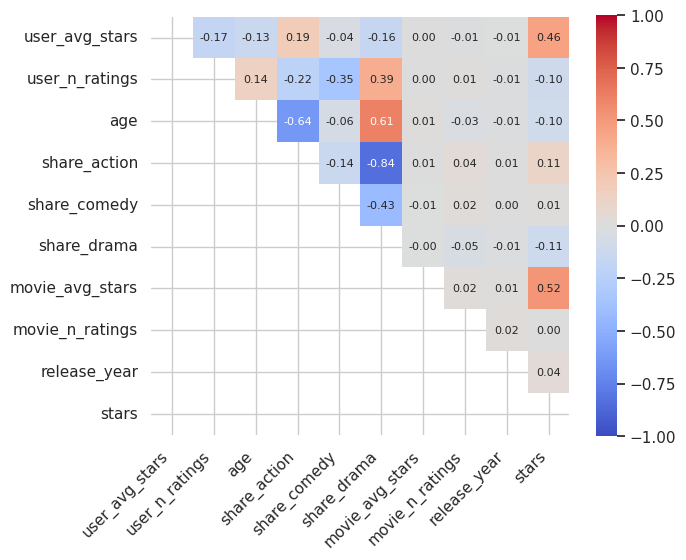

In [4]:
corr = dados.select_dtypes(include="number").corr()
mascara = np.tril(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
dados = dados.drop(columns="share_comedy")

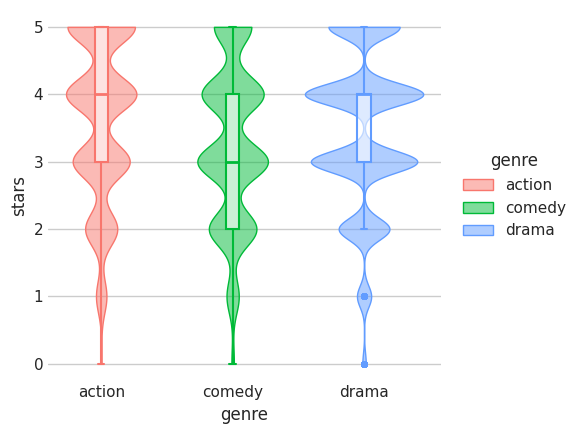

In [13]:
ordem = sorted(dados["genre"].unique())
paleta = dict(zip(ordem, ["#F8766D", "#00BA38", "#619CFF"]))
grupos = [dados.loc[dados["genre"] == g, "stars"].to_numpy() for g in ordem]


def largura_nrd0(x):
    sd = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    h = min(sd, iqr / 1.34) if iqr > 0 else sd
    return 0.9 * h * len(x) ** (-0.2)


curvas = []
for x in grupos:
    kde = gaussian_kde(x, bw_method=largura_nrd0(x) / np.std(x, ddof=1))
    grade = np.linspace(x.min(), x.max(), 512)
    curvas.append((grade, kde(grade)))
dens_max = max(d.max() for _, d in curvas)

fig, ax = plt.subplots(figsize=(6, 4.5))
for i, (g, (grade, dens)) in enumerate(zip(ordem, curvas)):
    meia_largura = dens / dens_max * 0.45
    ax.fill_betweenx(grade, i - meia_largura, i + meia_largura,
                     facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], linewidth=1)

caixas = ax.boxplot(grupos, positions=range(len(ordem)), widths=0.1, patch_artist=True,
                    manage_ticks=False)
for i, g in enumerate(ordem):
    cor = paleta[g]
    caixas["boxes"][i].set(facecolor=to_rgba("white", 0.6), edgecolor=cor, linewidth=1.5)
    caixas["medians"][i].set(color=cor, linewidth=2)
    for parte in ("whiskers", "caps"):
        for linha in caixas[parte][2 * i:2 * i + 2]:
            linha.set(color=cor, linewidth=1.5)
    caixas["fliers"][i].set(marker="o", markersize=4, markerfacecolor=cor, markeredgecolor=cor)

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels(ordem)
ax.set_yticks(range(0, 6))
ax.set_xlabel("genre")
ax.set_ylabel("stars")
ax.grid(axis="x", visible=False)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
ax.legend(handles=[Patch(facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], label=g) for g in ordem],
          title="genre", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.show()

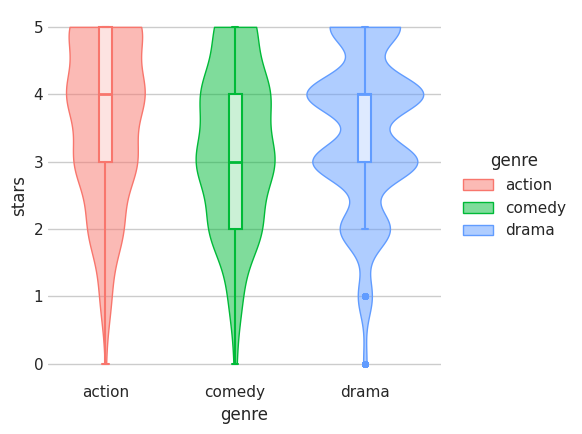

In [14]:
ordem = sorted(dados["genre"].unique())
paleta = dict(zip(ordem, ["#F8766D", "#00BA38", "#619CFF"]))
grupos = [dados.loc[dados["genre"] == g, "stars"].to_numpy() for g in ordem]

def largura_nrd0(x):
    sd = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    h = min(sd, iqr / 1.34) if iqr > 0 else sd
    return 0.9 * h * len(x) ** (-0.2)

# FATOR DE SUAVIZAÇÃO: Aumente este valor para deixar mais suave (ex: 1.5, 2.0)
fator_suavizacao = 1.8

curvas = []
for x in grupos:
    # Multiplicamos o resultado da largura de banda pelo fator para suavizar a curva
    largura_ajustada = (largura_nrd0(x) / np.std(x, ddof=1)) * fator_suavizacao
    kde = gaussian_kde(x, bw_method=largura_ajustada)
    grade = np.linspace(x.min(), x.max(), 512)
    curvas.append((grade, kde(grade)))
dens_max = max(d.max() for _, d in curvas)

fig, ax = plt.subplots(figsize=(6, 4.5))
for i, (g, (grade, dens)) in enumerate(zip(ordem, curvas)):
    meia_largura = dens / dens_max * 0.45
    ax.fill_betweenx(grade, i - meia_largura, i + meia_largura,
                     facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], linewidth=1)

caixas = ax.boxplot(grupos, positions=range(len(ordem)), widths=0.1, patch_artist=True,
                    manage_ticks=False)
for i, g in enumerate(ordem):
    cor = paleta[g]
    caixas["boxes"][i].set(facecolor=to_rgba("white", 0.6), edgecolor=cor, linewidth=1.5)
    caixas["medians"][i].set(color=cor, linewidth=2)
    for parte in ("whiskers", "caps"):
        for linha in caixas[parte][2 * i:2 * i + 2]:
            linha.set(color=cor, linewidth=1.5)
    caixas["fliers"][i].set(marker="o", markersize=4, markerfacecolor=cor, markeredgecolor=cor)

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels(ordem)
ax.set_yticks(range(0, 6))
ax.set_xlabel("genre")
ax.set_ylabel("stars")
ax.grid(axis="x", visible=False)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
ax.legend(handles=[Patch(facecolor=to_rgba(paleta[g], 0.5), edgecolor=paleta[g], label=g) for g in ordem],
          title="genre", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.show()

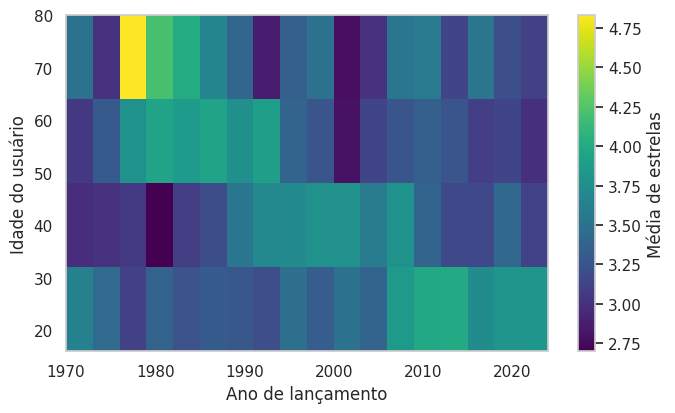

In [10]:
bins_x = np.arange(dados["release_year"].min(), dados["release_year"].max() + 3, 3)
bins_y = np.arange(dados["age"].min(), dados["age"].max() + 16, 16)
estatistica, bx, by, _ = binned_statistic_2d(
    dados["release_year"], dados["age"], dados["stars"],
    statistic="mean", bins=[bins_x, bins_y]
)
fig, ax = plt.subplots(figsize=(7, 4.3))
malha = ax.pcolormesh(bx, by, estatistica.T, cmap="viridis")
fig.colorbar(malha, ax=ax, label="Média de estrelas")
ax.set_xlabel("Ano de lançamento")
ax.set_ylabel("Idade do usuário")
plt.tight_layout()
plt.show()

# Modelagem